In [23]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iml.dungeon import Dungeon
from iml.agent import DungeonAgent
from iml.visualization import DungeonVisualization
from iml.dungeon_maker import make_treasure_room, make_underground_maze, make_underground_maze_with_meat

**Group members:**
- BALACHANDRAN Vanathy
- DOS SANTOS RAMOS Sarah Melyssa
- OZAN Saadet

## Part 1: Gridworld Environment

### 1.1 A drunken knight in a treasure room
### (a)
> Implement a stochastic policy where you select actions uniformly at random.

> Stochastic policy $(\pi)$ is a probability distribution that determines the probability of executing each action $(a)$ in a given state $(s)$

> In the case of selecting actions uniformly at random $\pi(a|s) = \frac {1}{4} = 0.25$  as there are 4 possible actions in each state : $[0, 1, 2, 3]$

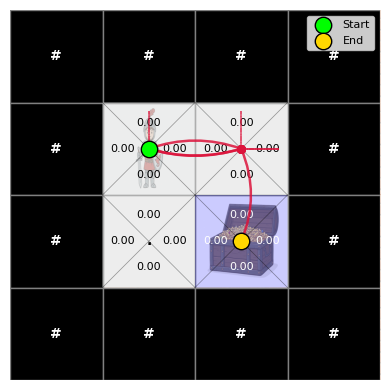

In [4]:
def my_reward_11(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    return 0.0

def my_action_11(state, q_value):
	# <implement your action here>
	return np.random.choice([0, 1, 2, 3])

def my_Q_update_11(agent, state, action, reward, next_state, dungeon):
    return None # use None for now

treasure_room = make_treasure_room()
vis_11 = DungeonVisualization(treasure_room)

drunken_knight = DungeonAgent(n_states=treasure_room.n_states, 
                             choose_action=my_action_11,
                             reward_func=my_reward_11,
                             update_q_values=my_Q_update_11)

# Run the agent for 1 episode & collect states, actions, rewards
states, actions, rewards = drunken_knight.run_episode(treasure_room, nstep=10, gamma=1.0)

# Show the map, Q-values, and path.
vis_11.show(states, actions, drunken_knight.q_values)

### (b)
> Observe how you move and draw a Markov decision process (MDP) diagram for all four non-wall states.

*(Insert your MDP diagram photo/figure here)*

### (c)
> Compute the theoretical probability distribution over a 2-step horizon analytically (without writing code) when you use the stochastic policy you implemented.

> The agent starts at $s^0 = (1, 1)$ under the stochastic policy $\pi(a|s) = 0.25$


> At t = 1 : he can either 
- go up --> hits the wall so he stays at (1,1)
- go down --> moves to (2,1)
- go left --> hit the wall so he stays at (1,1)
- go right --> moves to (1,2)

Hence the probabilities at t=1 : 
- $P(s^1 = (1,1) | s^0 = (1,1)) = 1/4 + 1/4 = 1/2$
- $P(s^1 = (1,2) | s^0 = (1,1)) = 1/4$
- $P(s^1 = (2,1) | s^0 = (1,1)) = 1/4$
- $P(s^1 = (2,2) | s^0 = (1,1)) = 0$

> t = 2 : 
- From $s^1 = (1,1) (weight = 1/2)$ : 
    - up / left : stays at (1,1) with prob $1/2 \times 1/2 = 1/4$
    - right : moves to (1,2) with prob $1/2 \times 1/4 = 1/8$
    - down : moves to (2,1) with prob $1/2 \times 1/4 = 1/8$

- From $s^1 = (1,2) (weight = 1/4)$ :
    - up : stays at (1,2) with prob $1/4 \times 1/4 = 1/16$
    - right : stays at (1,2) with prob $1/4 \times 1/4 = 1/16$
    - left : move to (1,1) with prob $1/4 \times 1/4 = 1/16$
    - down : move to goal to (2,2) with prob $1/4 \times 1/4 = 1/16$


- From $s^1 = (2,1) (weight = 1/4)$ :
    - up : move at (1,1) with prob $1/4 \times 1/4 = 1/16$
    - right : move to goal at (2,2) with prob $1/4 \times 1/4 = 1/16$
    - left : stays at (2,1) with prob $1/4 \times 1/4 = 1/16$
    - down : stays at (2,1) with prob $1/4 \times 1/4 = 1/16$


Thus the sum probabilities for each final state $s^2$ is : 
- (1, 1) : $1/4 + 1/16 + 1/16 = 3/8$
- (1,2) : $1/8 + 1/16 + 1/16 = 1/4$
- (2,1) : $1/8 + 1/16 + 1/16 = 1/4$
- (2,2) : $1/16 + 1/16 = 1/8$

So the theoretical probability distribution over states at time step $t = 2$ is : 
> $P(s^2 | s^0 = (1,1))$

> = 0.375 for s = (1,1) (start)

> = 0.25 for s = (1,2)

> = 0.25 for s = (2,1)

> = 0.125 for s = (2,2) (goal)

> = 0 for all other states




### (d)
> If you implement Q-learning with an episode length of 1 (`nstep = 1`) under current setup, will you manage to perform better? Why or why not? Explain your reasoning.

> No. The treasure requires at least two moves to reach ($P(s^1 = (2,2) | s^0 = (1,1)) = 0$), but `nstep = 1` allows only one move per episode. Each new episode starts again at the starting position, so the agent never reaches the treasure or learns from its reward. Therefore, Q-learning cannot improve the success rate in this setup.


### (e)
> For a dungeon of width $N$ and height $M$, what is the minimum number of steps required to reach the goal from the starting position? Why? 

> Assuming the dungeon has the same layout (starting point upper left square and the treasure lower right corner):   The minimum number of steps is:$$(N - 1) + (M - 1) = N + M - 2$$Because the agent has to take $N - 1$ steps horizontally and $M - 1$ steps vertically, following the concept of Manhattan distance.


---
### 1.2 A tricky knight in an underground maze

### (a)
> (a) Using your stochastic policy $\pi$, implement the Q-learning update with a discount factor ($\gamma = 1$) and a maximum episode length of 30 steps ($n_{\text{step}} = 30$). Run consecutive episodes without resetting the Q-table. Explain your observations on how the Q-values change relative to the goal and starting locations.

Episode 50
Success rate so far: 11.8%


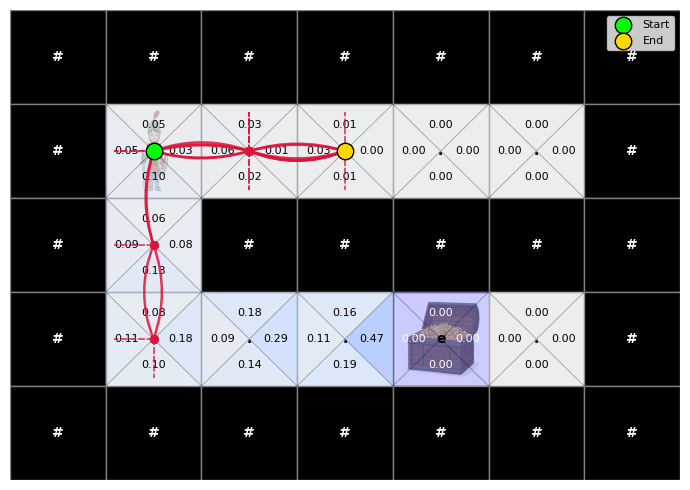

Episode 250
Success rate so far: 16.7%


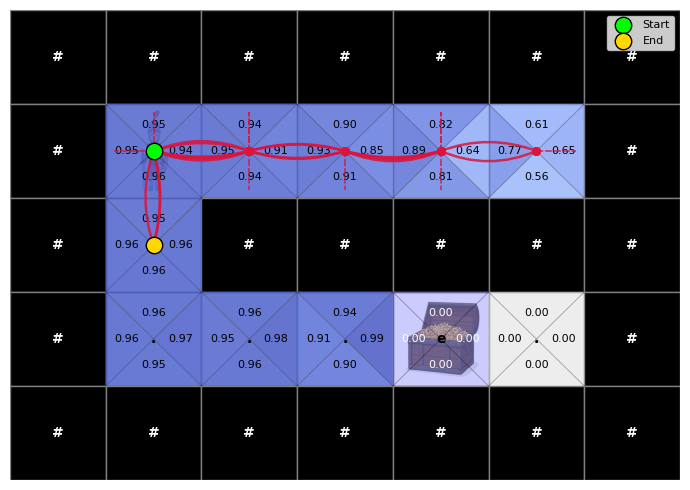

Episode 499
Success rate so far: 17.4%


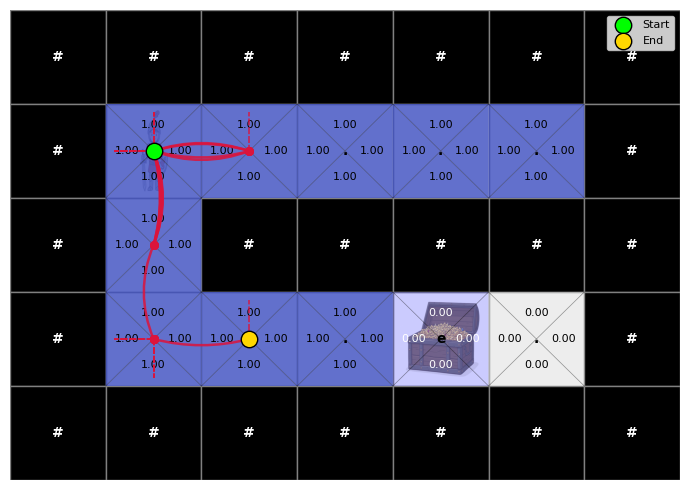

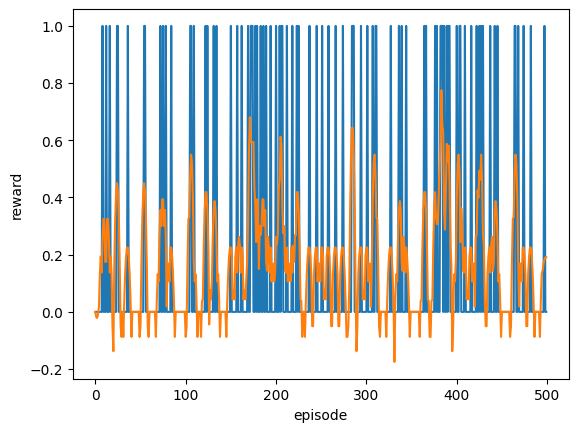

In [24]:
def my_reward_12(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    return 0.0

def my_action_12(state, q_values):
    return np.random.choice(4) 

def my_Q_update_12(agent, state, action, reward, next_state, dungeon):
    alpha = 0.1
    gamma = 1.0

    current_q = agent.q_values[action, state]

    if next_state == dungeon.end:
        max_next_q = 0.0
    else:
        max_next_q = np.max(agent.q_values[:, next_state])

    target = reward + gamma * max_next_q
    error = target - current_q
    new_q = current_q + alpha * error

    agent.q_values[action, state] = new_q
    return new_q

	# <implement your Q update here>
	# Hint: lecture 9, page 18 <20/29>
	# return ... (float)

underground_maze = make_underground_maze(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, 
                             choose_action=my_action_12,
                             reward_func=my_reward_12,
                             update_q_values=my_Q_update_12)

np.random.seed(42)
training_reward = []
episodes = 500

for episode in range(episodes):
    states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=30, gamma=1.0)
    total_reward = sum(rewards)
    training_reward.append(total_reward)
    
    if episode in [50, 250, 499]:
        print(f"Episode {episode}")
        print(
            f"Success rate so far: "
            f"{np.mean(training_reward):.1%}"
        )

        vis_12.show(
            states,
            actions,
            tricky_knight.q_values.copy()
        )
# program your knight here
# compute episodic reward
# append "training_reward"

# plot "training_reward"
vis_12.plot_training_reward(training_reward)

In each episode the agent either gets 1.0 if it finds the treasure within 30 steps, or 0.0 if it doesn't. The spikes occur at random interval throughout the 500 episides : this is because the actions are randomly selected (question 1.a), so the agent never exploits the Q-value to learn, even though the Q table is continuously updated. This also explains why the success rate is low even with more episodes.

With $\gamma = 1.0$, there is no penalty for taking longer paths. Any path that eventually reaches the treasure within the 30 steps allows the reward to propagate even to squares well outside of the optimal path. Since this dungeon is small, the reward signal will simply propagate everywhere the knight can reach, given enough training episodes.

### (b) By varying the discount factor $\gamma$, do you observe any differences? Summarize how the discount rate affects the results and explain why it is necessary.

#### $\gamma = 0.6$

Episode 50
Success rate so far: 11.8%


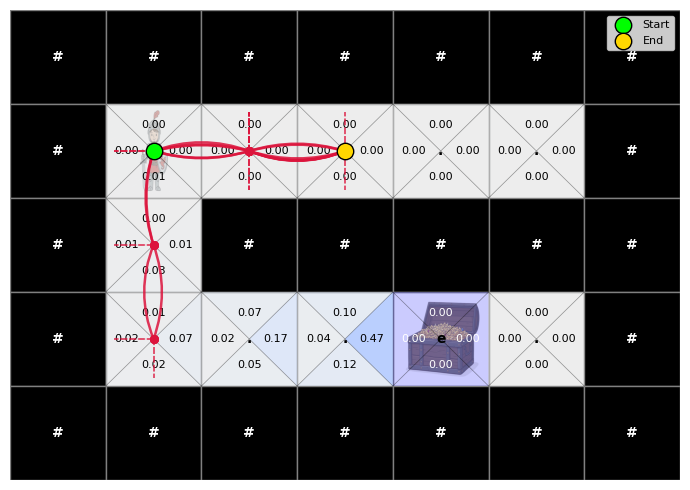

Episode 250
Success rate so far: 16.7%


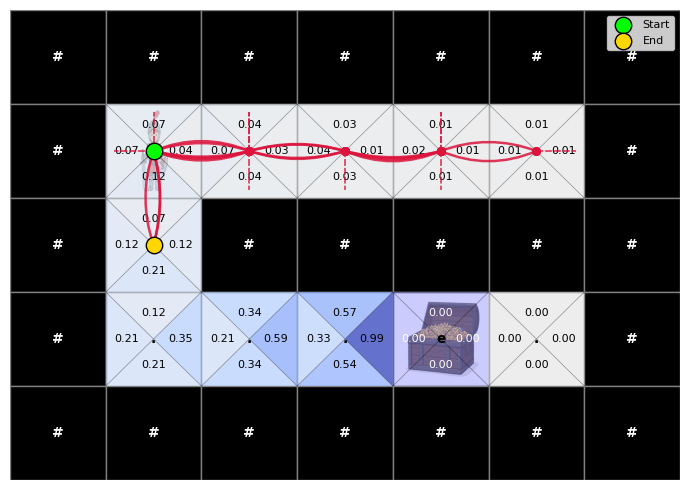

Episode 499
Success rate so far: 17.4%


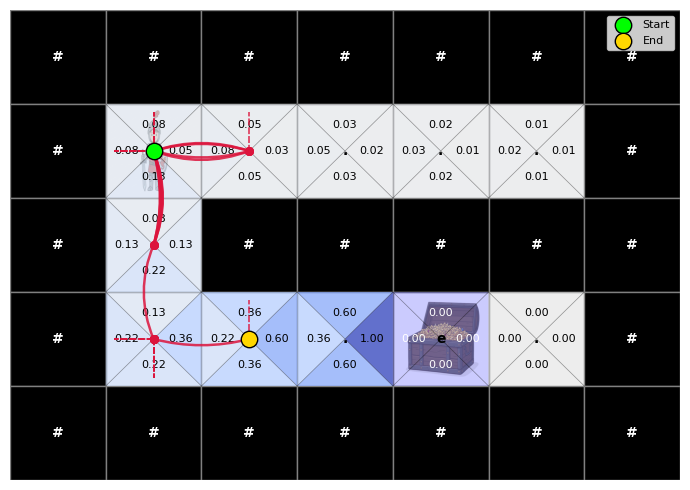

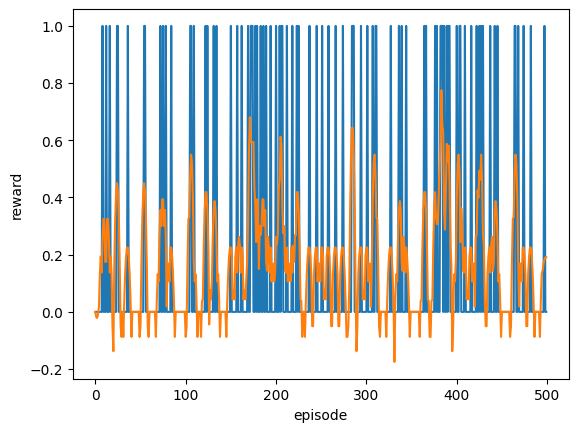

In [29]:
def my_Q_update_12(agent, state, action, reward, next_state, dungeon):
    alpha = 0.1
    gamma = 0.6

    current_q = agent.q_values[action, state]

    if next_state == dungeon.end:
        max_next_q = 0.0
    else:
        max_next_q = np.max(agent.q_values[:, next_state])

    target = reward + gamma * max_next_q
    error = target - current_q
    new_q = current_q + alpha * error

    agent.q_values[action, state] = new_q
    return new_q

underground_maze = make_underground_maze(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, 
                             choose_action=my_action_12,
                             reward_func=my_reward_12,
                             update_q_values=my_Q_update_12)

np.random.seed(42)
training_reward = []
episodes = 500

for episode in range(episodes):
    states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=30, gamma=0.6)
    total_reward = sum(rewards)
    training_reward.append(total_reward)
    
    if episode in [50, 250, 499]:
        print(f"Episode {episode}")
        print(
            f"Success rate so far: "
            f"{np.mean(training_reward):.1%}"
        )

        vis_12.show(
            states,
            actions,
            tricky_knight.q_values.copy()
        )

vis_12.plot_training_reward(training_reward)

#### $\gamma = 0.0$

Episode 50
Success rate so far: 11.8%


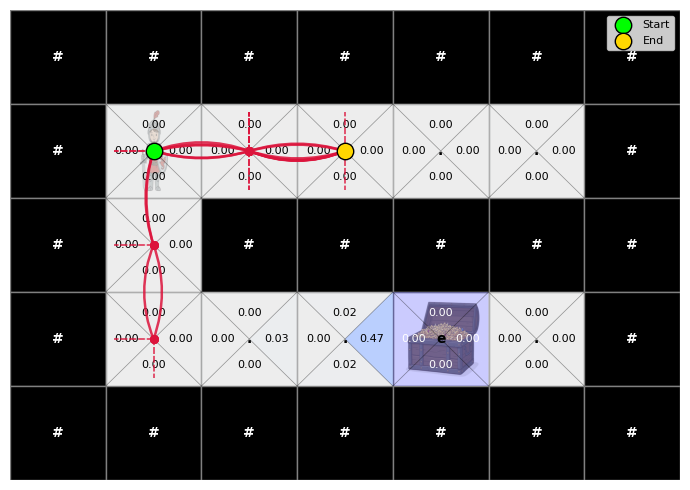

Episode 250
Success rate so far: 16.7%


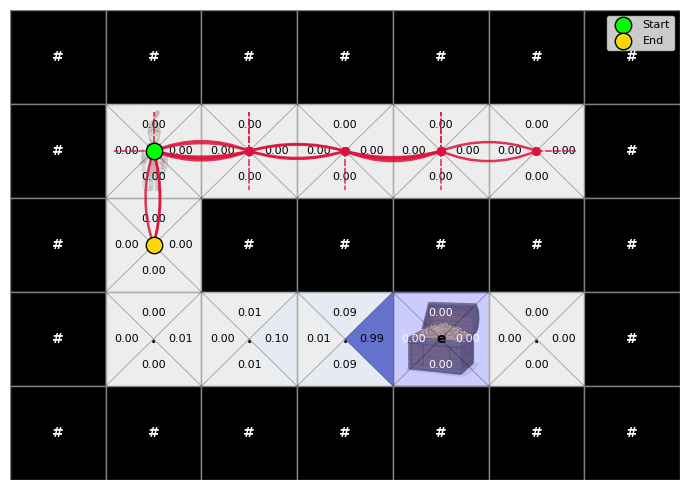

Episode 499
Success rate so far: 17.4%


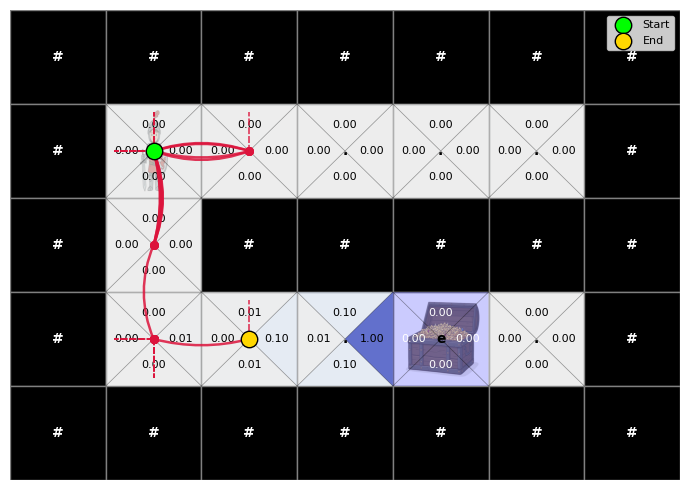

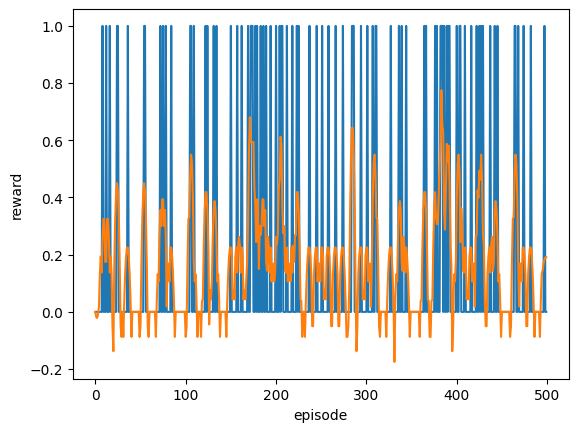

In [30]:
def my_reward_12(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    return 0.0

def my_action_12(state, q_values):
    return np.random.choice(4) 

def my_Q_update_12(agent, state, action, reward, next_state, dungeon):
    alpha = 0.1
    gamma = 0.1

    current_q = agent.q_values[action, state]

    if next_state == dungeon.end:
        max_next_q = 0.0
    else:
        max_next_q = np.max(agent.q_values[:, next_state])

    target = reward + gamma * max_next_q
    error = target - current_q
    new_q = current_q + alpha * error

    agent.q_values[action, state] = new_q
    return new_q

	# <implement your Q update here>
	# Hint: lecture 9, page 18 <20/29>
	# return ... (float)

underground_maze = make_underground_maze(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, 
                             choose_action=my_action_12,
                             reward_func=my_reward_12,
                             update_q_values=my_Q_update_12)

np.random.seed(42)
training_reward = []
episodes = 500

for episode in range(episodes):
    states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=30, gamma=0.1)
    total_reward = sum(rewards)
    training_reward.append(total_reward)
    
    if episode in [50, 250, 499]:
        print(f"Episode {episode}")
        print(
            f"Success rate so far: "
            f"{np.mean(training_reward):.1%}"
        )

        vis_12.show(
            states,
            actions,
            tricky_knight.q_values.copy()
        )
# program your knight here
# compute episodic reward
# append "training_reward"

# plot "training_reward"
vis_12.plot_training_reward(training_reward)

gamma = 0.99 : 
slight improvement in reward distribution compared to gamma = 1.0, but all states still get a q-value

gamma = 0.6 : 
scarce reward distribution : limited propagation. the rewards becomes smaller for states farther from the treasure

gamma = 0.0 : 
only yhe immediate rewards matter --> only the actions that reach the treasure have a reward (1.0) wh

### (c)
> Implement an $\epsilon$-greedy policy for your agent by varying $\epsilon$. Plot the sum of discounted rewards per episode over 100 training runs and explain your observations.

Episode 1
Success rate so far: 0.0%


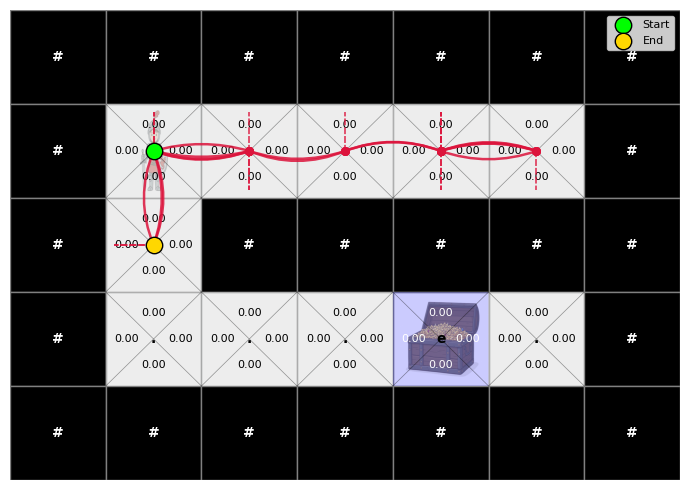

Episode 50
Success rate so far: 92.2%


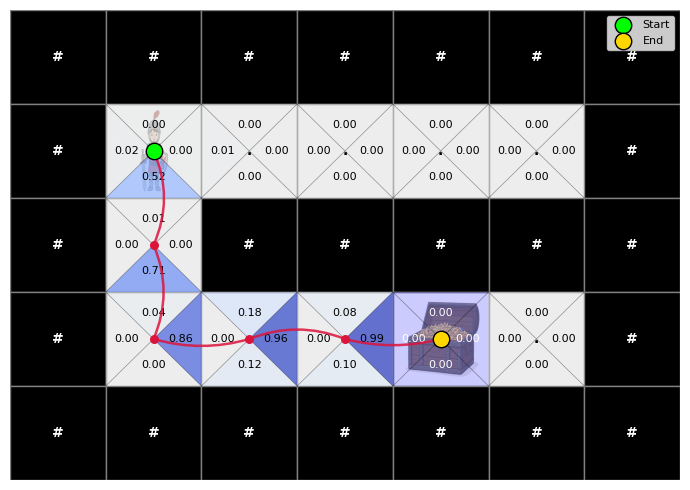

Episode 99
Success rate so far: 96.0%


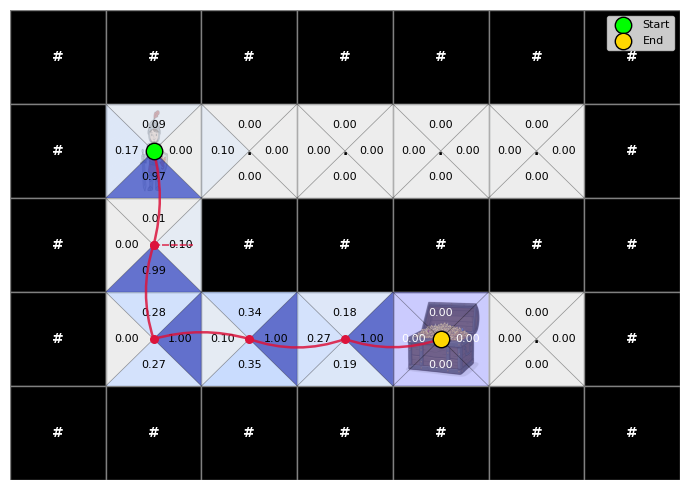

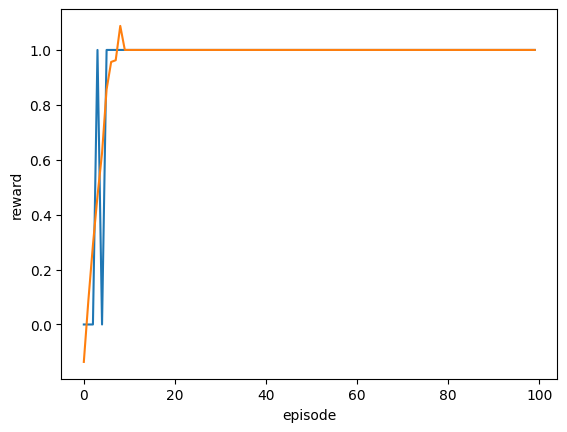

In [33]:
def my_reward_12(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    return 0.0

def my_action_12(state, q_values, epsilon=0.1):
    if np.random.rand() < epsilon:
        return np.random.choice(4)
    else:
        state_q = q_values[:, state]
        max_q = np.max(state_q)
        best_actions = np.where(state_q == max_q)[0]
        return np.random.choice(best_actions)

def my_Q_update_12(agent, state, action, reward, next_state, dungeon):
    alpha = 0.1
    gamma = 1.0

    current_q = agent.q_values[action, state]

    if next_state == dungeon.end:
        max_next_q = 0.0
    else:
        max_next_q = np.max(agent.q_values[:, next_state])

    target = reward + gamma * max_next_q
    error = target - current_q
    new_q = current_q + alpha * error

    agent.q_values[action, state] = new_q
    return new_q

underground_maze = make_underground_maze(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, 
                             choose_action=my_action_12,
                             reward_func=my_reward_12,
                             update_q_values=my_Q_update_12)

np.random.seed(42)
training_reward = []
episodes = 100

for episode in range(episodes):
    states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=30, gamma=1.0)
    total_reward = sum(rewards)
    training_reward.append(total_reward)
    
    if episode in [1, 50, 99]:
        print(f"Episode {episode}")
        print(
            f"Success rate so far: "
            f"{np.mean(training_reward):.1%}"
        )

        vis_12.show(
            states,
            actions,
            tricky_knight.q_values.copy()
        )

vis_12.plot_training_reward(training_reward)

Episode 1
Success rate so far: 0.0%


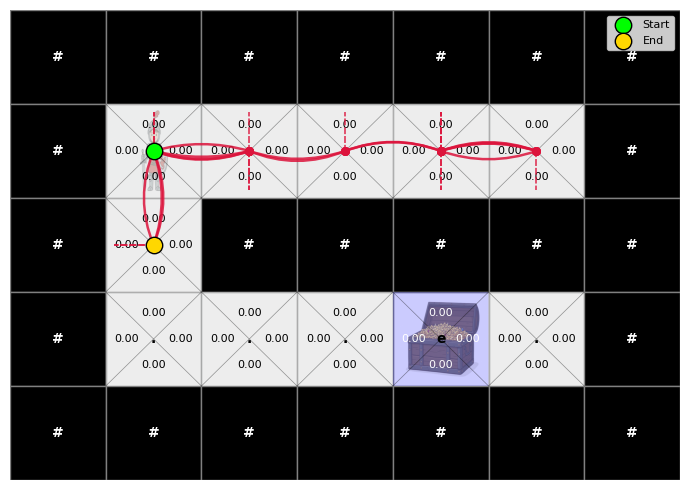

Episode 50
Success rate so far: 88.2%


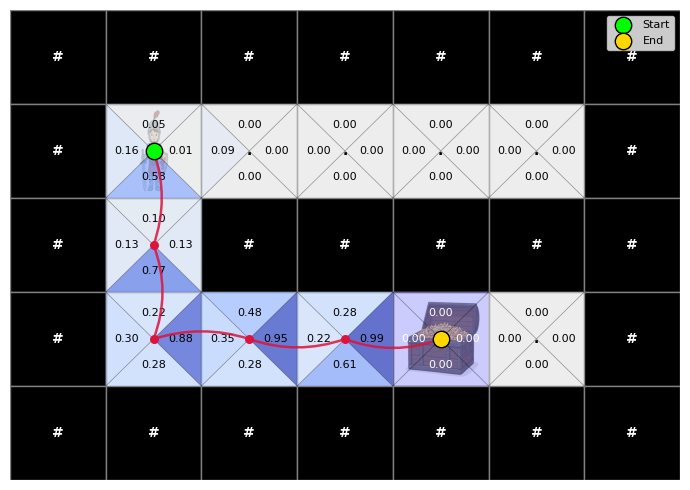

Episode 99
Success rate so far: 94.0%


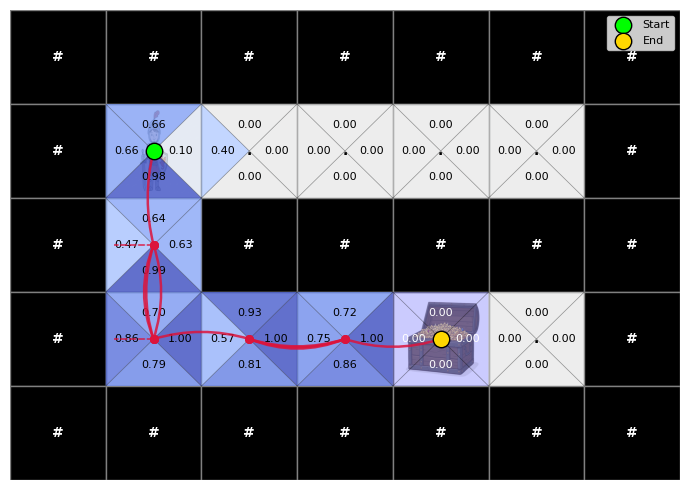

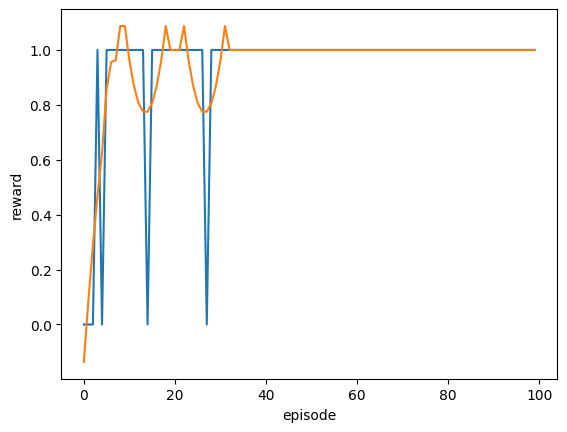

In [34]:
def my_reward_12(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    return 0.0

def my_action_12(state, q_values, epsilon=0.5):
    if np.random.rand() < epsilon:
        return np.random.choice(4)
    else:
        state_q = q_values[:, state]
        max_q = np.max(state_q)
        best_actions = np.where(state_q == max_q)[0]
        return np.random.choice(best_actions)

def my_Q_update_12(agent, state, action, reward, next_state, dungeon):
    alpha = 0.1
    gamma = 1.0

    current_q = agent.q_values[action, state]

    if next_state == dungeon.end:
        max_next_q = 0.0
    else:
        max_next_q = np.max(agent.q_values[:, next_state])

    target = reward + gamma * max_next_q
    error = target - current_q
    new_q = current_q + alpha * error

    agent.q_values[action, state] = new_q
    return new_q

underground_maze = make_underground_maze(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, 
                             choose_action=my_action_12,
                             reward_func=my_reward_12,
                             update_q_values=my_Q_update_12)

np.random.seed(42)
training_reward = []
episodes = 100

for episode in range(episodes):
    states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=30, gamma=1.0)
    total_reward = sum(rewards)
    training_reward.append(total_reward)
    
    if episode in [1, 50, 99]:
        print(f"Episode {episode}")
        print(
            f"Success rate so far: "
            f"{np.mean(training_reward):.1%}"
        )

        vis_12.show(
            states,
            actions,
            tricky_knight.q_values.copy()
        )

vis_12.plot_training_reward(training_reward)

Episode 1
Success rate so far: 0.0%


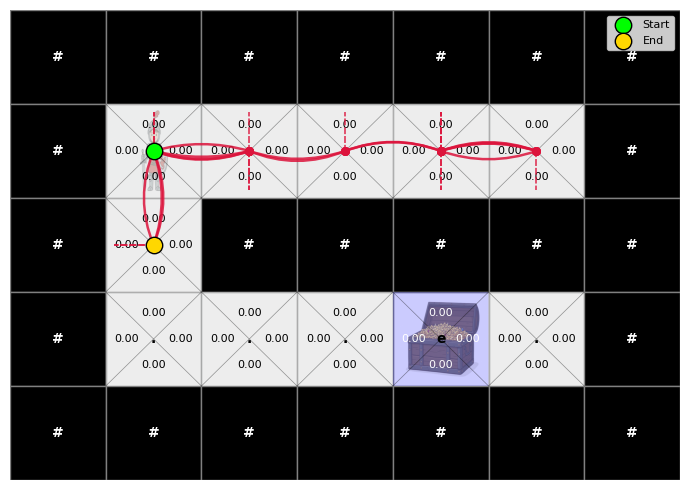

Episode 50
Success rate so far: 23.5%


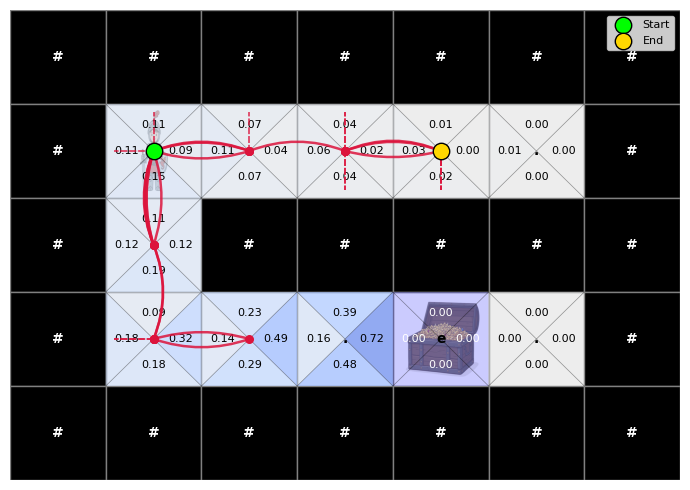

Episode 99
Success rate so far: 25.0%


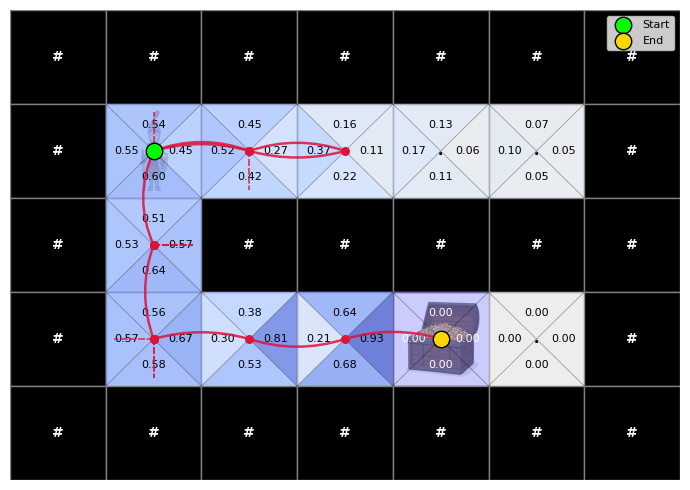

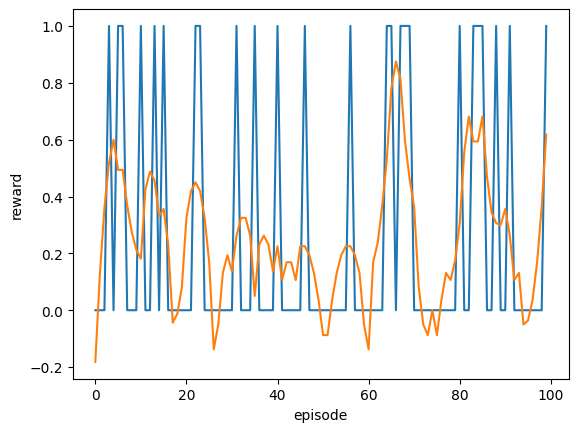

In [35]:
def my_reward_12(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    return 0.0

def my_action_12(state, q_values, epsilon=1.0):
    if np.random.rand() < epsilon:
        return np.random.choice(4)
    else:
        state_q = q_values[:, state]
        max_q = np.max(state_q)
        best_actions = np.where(state_q == max_q)[0]
        return np.random.choice(best_actions)

def my_Q_update_12(agent, state, action, reward, next_state, dungeon):
    alpha = 0.1
    gamma = 1.0

    current_q = agent.q_values[action, state]

    if next_state == dungeon.end:
        max_next_q = 0.0
    else:
        max_next_q = np.max(agent.q_values[:, next_state])

    target = reward + gamma * max_next_q
    error = target - current_q
    new_q = current_q + alpha * error

    agent.q_values[action, state] = new_q
    return new_q

underground_maze = make_underground_maze(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, 
                             choose_action=my_action_12,
                             reward_func=my_reward_12,
                             update_q_values=my_Q_update_12)

np.random.seed(42)
training_reward = []
episodes = 100

for episode in range(episodes):
    states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=30, gamma=1.0)
    total_reward = sum(rewards)
    training_reward.append(total_reward)
    
    if episode in [1, 50, 99]:
        print(f"Episode {episode}")
        print(
            f"Success rate so far: "
            f"{np.mean(training_reward):.1%}"
        )

        vis_12.show(
            states,
            actions,
            tricky_knight.q_values.copy()
        )

vis_12.plot_training_reward(training_reward)

By implementing the $\epsilon$-greedy policy, we see that the higher $\epsilon$, the more the agent tends to choose random actions (similar to our drunken knight).

The closer $\epsilon$ is to 0, the faster the reward converges towards 1.0 and remains at that value, and the success rate quickly arises. Indeed, the agent actively uses the learned value estimates to efficently reach the goal.

### (d)
> Is a single training run sufficient to evaluate and compare an agent’s performance across different hyperparameter settings? Specifically: (i) Will an agent reach the goal on every evaluation episode? Explain why or why not. (ii) Under what specific conditions would RL training and evaluation results be strictly deterministic and reproducible? And (iii) Given these factors, how should an RL agent's performance be properly evaluated and compared, both when those deterministic conditions are met and when they are not?

### (e)
> Recreate the maze using `make_underground_maze_with_meat()`, update the reward function, set $\epsilon = 0.9$, $n_{\text{step}} = 50$, and $\gamma = 0.95$, and run the agent for 100 to 200 training runs. Explain your observations regarding your strategy (Q-values) and behavior.

Episode 1
Success rate so far: 50.0%


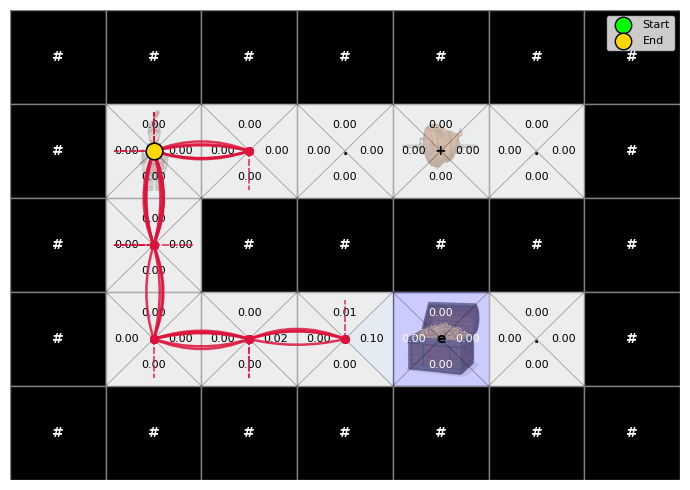

Episode 50
Success rate so far: 379.4%


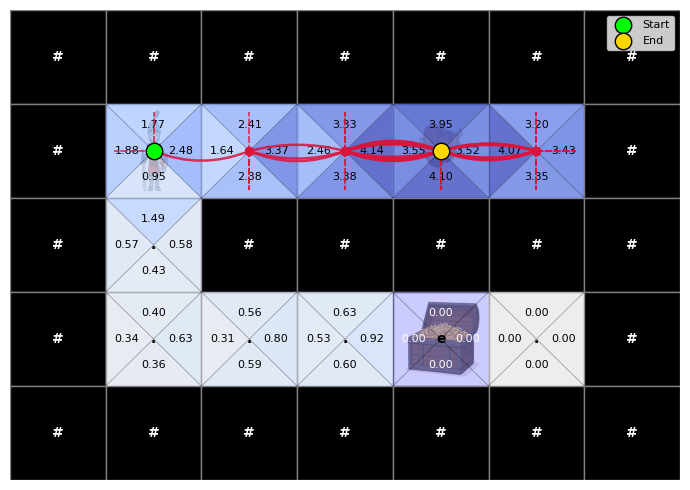

Episode 99
Success rate so far: 461.5%


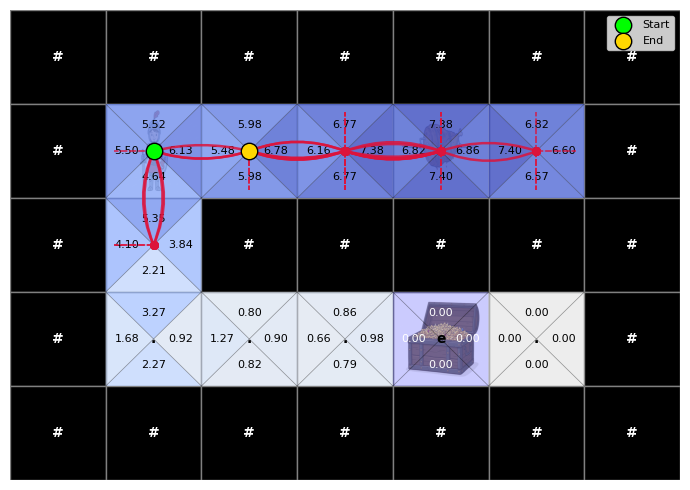

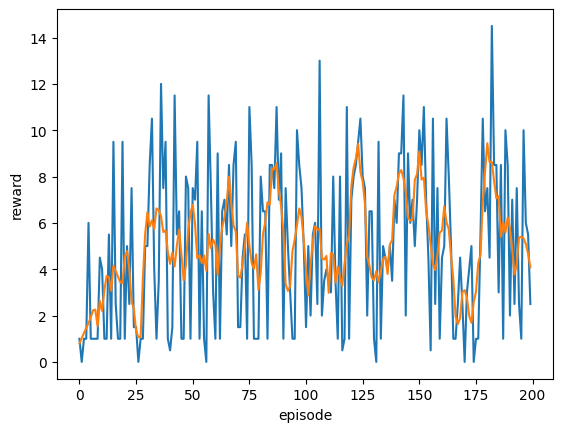

In [36]:
def my_reward_12(state, action, next_state, dungeon):
    if next_state == dungeon.end:
        return 1.0
    if dungeon.tiles[next_state] == "+":
        return 0.5
    return 0.0

def my_action_12(state, q_values, epsilon=0.9):
    if np.random.rand() < epsilon:
        return np.random.choice(4)
    else:
        state_q = q_values[:, state]
        max_q = np.max(state_q)
        best_actions = np.where(state_q == max_q)[0]
        return np.random.choice(best_actions)

def my_Q_update_12(agent, state, action, reward, next_state, dungeon):
    alpha = 0.1
    gamma = 0.95

    current_q = agent.q_values[action, state]

    if next_state == dungeon.end:
        max_next_q = 0.0
    else:
        max_next_q = np.max(agent.q_values[:, next_state])

    target = reward + gamma * max_next_q
    error = target - current_q
    new_q = current_q + alpha * error

    agent.q_values[action, state] = new_q
    return new_q

underground_maze = make_underground_maze_with_meat(p_slippery=0.0)
vis_12 = DungeonVisualization(underground_maze)

tricky_knight = DungeonAgent(n_states=underground_maze.n_states, 
                             choose_action=my_action_12,
                             reward_func=my_reward_12,
                             update_q_values=my_Q_update_12)

np.random.seed(42)
training_reward = []
episodes = 200

for episode in range(episodes):
    states, actions, rewards = tricky_knight.run_episode(underground_maze, nstep=50, gamma=0.95)
    total_reward = sum(rewards)
    training_reward.append(total_reward)
    
    if episode in [1, 50, 99]:
        print(f"Episode {episode}")
        print(
            f"Success rate so far: "
            f"{np.mean(training_reward):.1%}"
        )

        vis_12.show(
            states,
            actions,
            tricky_knight.q_values.copy()
        )
vis_12.plot_training_reward(training_reward)

The meat tile immediately rewards the agent with 0.5, and can be reached multiple time (contrary to the treasure tile) causing the agent to target the meat exclusively even though the knight acts randomly 90% of the time. As a result it no longer achieves its main target of reaching the treasure as the tiles surronding the meat get higher Q-values. This behaviour demonstrates reward hacking.

> (f) Compare the state values $V(s)$ when you go directly to the treasure (e), collects free meat as you observed (+), or do both. Explain your results mathematically.


> (g) How might you modify the reward function or environment design to prevent this *reward hacking*? Propose and explain a solution. (Bonus)

## Part 2: Bayesian Decision-Making in Multi-Armed Bandits

### 2.1 Bayesian Estimation of Arm Rewards

### (a)
> Starting from Bayes' theorem and the Bernoulli likelihood, derive the posterior distribution $p(\theta \mid D)$ and identify its updated parameters. Hence, show that the Beta distribution is a conjugate prior to the Bernoulli likelihood. 

### (b)
> Suppose the prior is $(\beta(2,2))$. After ten pulls, the arm produces seven successes and three failures. Compute the posterior distribution and posterior mean. Show that, in general, the posterior mean can be expressed as a weighted average of the prior mean and the empirical success rate. Interpret the weights and explain how they change as the number of observations increases

### 2.2 Learning with Thompson Samplin

### (a)
> Implement a five-armed Bernoulli bandit environment that generates binary rewards using the given success probabilities. Then implement a Thompson sampling agent that maintains the posterior parameters for each arm, selects actions using posterior sampling, and updates the corresponding posterior after receiving each reward. 

### (b)
> Using the results from part (a), plot the evolution of the posterior mean estimates for all five arms as a function of time; visualize the posterior distributions; discuss how the posterior means and distributions evolve; and explain why some arms become more certain about their estimated success probabilities than others.

### 2.3 Experimental Evaluation and Exploration

### (a)
> Perform 100 independent trials of Thompson sampling, each consisting of 2,000 decisions. Initialize a new agent with the same priors at the beginning of every trial.

### (b)
> Derive the agent's expected reward per decision and its expected instantaneous pseudo-regret. Hence, derive the expected cumulative pseudo-regret $\mathbb{E}[\mathcal{R}_T]$. How does it grow with $T$, assuming $\epsilon$ remains fixed and the greedy choice remains optimal? (Bonus)

### (c)
> Compare $\epsilon$-greedy exploration with Thompson sampling. Explain why Thompson sampling may select an arm with a lower posterior mean and how its exploration behavior changes as more observations accumulate.